<small>Dataset: uber.csv</small>

# Q09. Uber EDA PCA Regression

Inspect Uber fares, clean invalid records and compare linear regression with and without PCA.


## Question from Classroom

Uber Fare Prediction Using PCA and EDA 
Problem statement: Analyze Uber fare data and investigate whether PCA can reduce 
dimensionality while maintaining acceptable prediction performance. 
Dataset: Uber Fares Dataset — Kaggle 
Tasks to be performed: 
3. Load the dataset and inspect its dimensions, data types, missing values and summary 
statistics. 
4. Perform EDA using appropriate plots and identify outliers or invalid records. 
5. Prepare relevant features and the fare amount as the target variable. 
6. Split the data into training and testing sets, and standardize the features where 
required. 
7. Apply PCA and select components using explained variance. 
8. Train comparable regression models with and without PCA. 
9. Compare R², RMSE and MAE, and interpret the results.


## Understand before coding

Load -> inspect/plot -> remove invalid rows -> select features/target -> split -> scale on training -> compare original and PCA regressions.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 7 listed tasks → 7 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load the dataset and inspect its dimensions, data types, missing values and summary statistics.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
df=pd.read_csv("data/uber.csv")

print("Shape:",df.shape)
print(df.head())
df.info()
print("Missing values:\n",df.isna().sum())
print("Summary:\n",df.describe(include="all").T)


Shape: (200000, 9)
   Unnamed: 0  ...  passenger_count
0    24238194  ...                1
1    27835199  ...                1
2    44984355  ...                1
3    25894730  ...                3
4    17610152  ...                5

[5 rows x 9 columns]
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB
Missing values:
 Unnamed: 0           0
key   

## Task 2. Perform EDA using appropriate plots and identify outliers or invalid records.

This block implements the task above. Variables from earlier blocks are reused.


09_Uber_EDA_PCA_Regression.ipynb task 2:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.


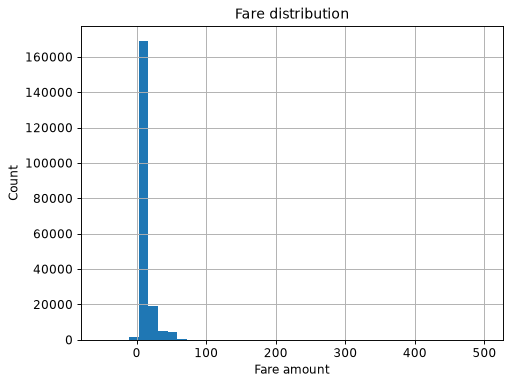

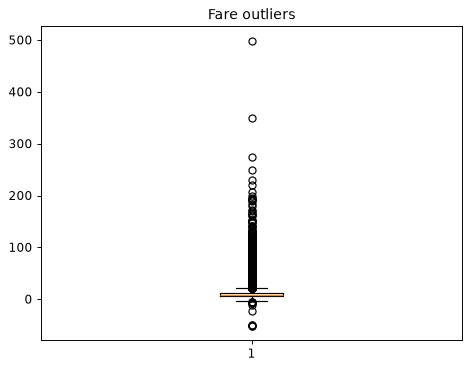

In [2]:
df["fare_amount"].hist(bins=40)
plt.xlabel("Fare amount"); plt.ylabel("Count"); plt.title("Fare distribution"); plt.show()
plt.boxplot(df["fare_amount"].dropna())
plt.title("Fare outliers"); plt.show()


coordinates = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]
for column in coordinates + ["fare_amount", "passenger_count"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce", utc=True)
df = df.dropna(subset=coordinates + ["fare_amount", "passenger_count", "pickup_datetime"])
df = df[(df["fare_amount"] > 0) & df["passenger_count"].between(1,6)].copy()
for column in coordinates:
    limit = 90 if "latitude" in column else 180
    df = df[df[column].between(-limit, limit) & (df[column] != 0)]
df["hour"] = df["pickup_datetime"].dt.hour
df["weekday"] = df["pickup_datetime"].dt.dayofweek


## Task 3. Prepare relevant features and the fare amount as the target variable.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
X=df[coordinates+["passenger_count","hour","weekday"]]
y=df["fare_amount"]
print("Predictors:",X.columns.tolist(),"Target: fare_amount")


Predictors: ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'hour', 'weekday'] Target: fare_amount


## Task 4. Split the data into training and testing sets, and standardize the features where required.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
medians=X_train.median()
X_train=X_train.fillna(medians)
X_test=X_test.fillna(medians)

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
train_scaled=scaler.fit_transform(X_train)
test_scaled=scaler.transform(X_test)


## Task 5. Apply PCA and select components using explained variance.

This block implements the task above. Variables from earlier blocks are reused.


Original features: 7 Retained components: 4
Explained variance: [0.55841193 0.15573454 0.14429555 0.12850822]


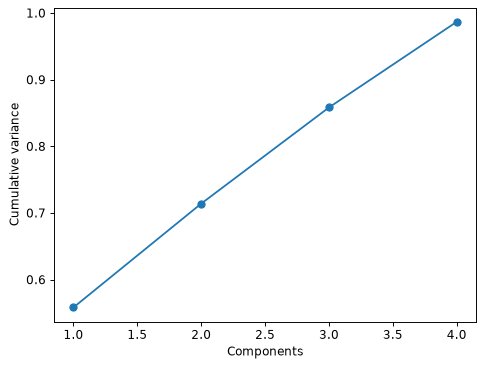

In [5]:
from sklearn.decomposition import PCA
pca=PCA(n_components=0.95)
train_pca=pca.fit_transform(train_scaled)
test_pca=pca.transform(test_scaled)
print("Original features:",X.shape[1],"Retained components:",pca.n_components_)
print("Explained variance:",pca.explained_variance_ratio_)
plt.plot(range(1,pca.n_components_+1),np.cumsum(pca.explained_variance_ratio_),"o-")
plt.xlabel("Components");plt.ylabel("Cumulative variance");plt.show()


## Task 6. Train comparable regression models with and without PCA.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
original_model=LinearRegression().fit(train_scaled,y_train)
pca_model=LinearRegression().fit(train_pca,y_train)
original_prediction=original_model.predict(test_scaled)
pca_prediction=pca_model.predict(test_pca)


## Task 7. Compare R², RMSE and MAE, and interpret the results.

This block implements the task above. Variables from earlier blocks are reused.


In [7]:
results=[]
for name,pred in [("Without PCA",original_prediction),("With PCA",pca_prediction)]:
    results.append({"Model":name,"R2":r2_score(y_test,pred),
      "RMSE":np.sqrt(mean_squared_error(y_test,pred)),"MAE":mean_absolute_error(y_test,pred)})
print(pd.DataFrame(results).to_string(index=False))
print("Compare errors and retained features. PCA does not guarantee better prediction.")


      Model       R2     RMSE      MAE
Without PCA 0.001018 9.656303 5.999787
   With PCA 0.000771 9.657495 6.000269
Compare errors and retained features. PCA does not guarantee better prediction.


## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What is linear regression?**

It fits y_hat = b0 + b1*x1 + ... + bp*xp, normally by minimizing the sum of squared training residuals.

**10. What are intercept and coefficients?**

The intercept is the predicted value when encoded inputs are zero. A coefficient describes the change in prediction per unit of that feature, holding the others fixed; association does not prove causation.

**11. Define MAE and RMSE.**

MAE=mean(abs(y-y_hat)). RMSE=sqrt(mean((y-y_hat)^2)). Both use the target units; lower is better. RMSE penalizes large errors more strongly.

**12. What is R2?**

R2=1-SSE/SST. A perfect prediction scores 1. A negative score means worse squared error than predicting the test target mean. It is not accuracy or a percentage of correct records.

**13. How do I interpret actual vs predicted?**

Points near the diagonal indicate small errors. Systematic curves or large scatter suggest model limitations. Do not invent a good score when the dataset has weak signal.

**14. What does PCA do?**

Principal Component Analysis replaces correlated input features by orthogonal components ordered by explained variance. It does not use the target.

**15. Why standardize before PCA?**

Variance depends on units. Scaling prevents a large-unit feature from dominating only because of its measurement scale.

**16. What does n_components=0.95 mean?**

Retain enough principal components to explain at least about 95% of training feature variance. This does not mean 95% prediction accuracy.

**17. Where is PCA fitted?**

On standardized training features only. Apply that fitted PCA to the test features using transform().

**18. What makes this comparison fair?**

Both models use the same split, preprocessing statistics, regressor type and test metrics. Only PCA is added to the second model.

**19. Does PCA always improve prediction?**

No. A low-variance direction may be predictive of y, so discarding it can hurt performance. Compare R2, RMSE and MAE rather than assuming an improvement.

**20. Does fewer components guarantee a faster complete workflow?**

No. PCA itself costs time. The table reports a single timing including PCA fitting/transformation for the PCA branch; timing also depends on hardware and warm-up.

**21. Is PCA feature selection?**

No. Each component is a linear combination of original features, so interpretation is less direct.

**22. Which columns are used?**

Pickup/dropoff longitude and latitude, passenger count, pickup hour and weekday. fare_amount is y. The key, row identifier and raw timestamp string are excluded.

**23. Which records are invalid?**

Missing required values, nonpositive fare, passenger count outside 1..6, out-of-range or zero coordinates. These rules are explicit practice assumptions; global coordinate validity does not prove a plausible local trip.

**24. Why show outliers?**

Extreme fares and coordinates can distort regression. Investigate them and justify filters rather than removing every large fare automatically.


### Task-to-code map

- **Block 1:** Load the dataset and inspect its dimensions, data types, missing values and summary statistics.
- **Block 2:** Perform EDA using appropriate plots and identify outliers or invalid records.
- **Block 3:** Prepare relevant features and the fare amount as the target variable.
- **Block 4:** Split the data into training and testing sets, and standardize the features where required.
- **Block 5:** Apply PCA and select components using explained variance.
- **Block 6:** Train comparable regression models with and without PCA.
- **Block 7:** Compare R², RMSE and MAE, and interpret the results.
